**ASSIGNMENT 1 (70112,IMPERIAL)**

<div style="font-family: 'Times New Roman', serif;">

**European Call option**

$T$: maturity  
$K$: strike price  
$(S_t)_{t\geq0}$: underlying asset  

*(by no-arbitrage arguments) option value is the expected value of the payout (when not considering interest rate)*
$$
\mathrm{C}(S_0, K, T) 
= \mathbb{E}\Big[(S_T-K, 0)_{+}\Big] 
= \mathbb{E}\Big[(S_{T}-K)\mathbb{1}_{\{S_T\geq K\}} + 0\cdot\boldsymbol{1}_{\{S_T< K\}}\Big]
$$

</div>

<div style="font-family: 'Times New Roman', serif;">


$(W_t)_{t\geq0}$: brownian motion which satisfies:  
    1) $W_0 = 0$ almost surely  
    2) $W_t - W_s ~ \mathcal{N}(0, t-s)  \forall 0\leq s\leq t$  
    3) $\Delta W_t$ are independent
  
$Z$: standard Gaussian random variable
</br>  

**Value of the underlying asset value (Assuming (Driftless) Geometric Brownian Motion)**

$$
S_t
 = S_0\exp\left\{-\frac{\sigma^2 t}{2} + \sigma W_t\right\}
  \stackrel{d}{=} S_0\exp\left\{-\frac{\sigma^2 t}{2} + \sigma Z\sqrt{t}\right\}
$$

</div>

<div style="font-family: 'Times New Roman', serif;">

**Value of a European Call Option at time zero (Black-Scholes)**  

$$
\mathrm{C}^{\mathrm{BS}}(S_0, K, T;\sigma) = \mathbb{E}\Big[\max(S_{T} - K, 0)\Big]
 = S_0\Big(\mathcal{N}(d_{+}) - \mathrm{e}^{k}\mathcal{N}(d_{-})\Big),
$$
where
$$
d_{\pm} = \frac{-k}{\sigma\sqrt{T}} \pm\frac{\sigma\sqrt{T}}{2}
$$  


$k:= log(K/S_0)$  
$\sigma$: volatility of returns of the underlying  
$\mathcal{N}(\cdot)$: CDF of the standard normal distribution  
$$\mathcal{N}(x) = \frac{1}{\sqrt{2\pi}}\int_{-\infty}^{x}\exp\left\{-\frac{z^2}{2}\right\}\mathrm{d}z$$

</div>

<div style="font-family: 'Times New Roman', serif;">  

#### 1. Pricing by closed-form formula  

</div>

In [4]:
from scipy.stats import norm
import numpy as np

def blackscholes_call(S0, K, sigma, T):
    '''
    #Inputs:
    S0: initial stock price
    K: strike
    sigma: instantaneous volatility
    T: time to maturity
    #Output:
    Black-Scholes Call price
    '''

    k = np.log(K/S0)
    dp = -k/(sigma*np.sqrt(T)) + sigma*np.sqrt(T)/2
    dm = -k/(sigma*np.sqrt(T)) - sigma*np.sqrt(T)/2

    return S0*(norm.cdf(dp) - np.exp(k)*norm.cdf(dm))  #norm.cdf : cdf of normal distribution given x

In [5]:
S0, K, sigma, T = 100., 100., 0.2, 1.
print("Black-Scholes Call option price:", blackscholes_call(S0,K,sigma,T))

Black-Scholes Call option price: 7.965567455405798


Text(0, 0.5, 'Price')

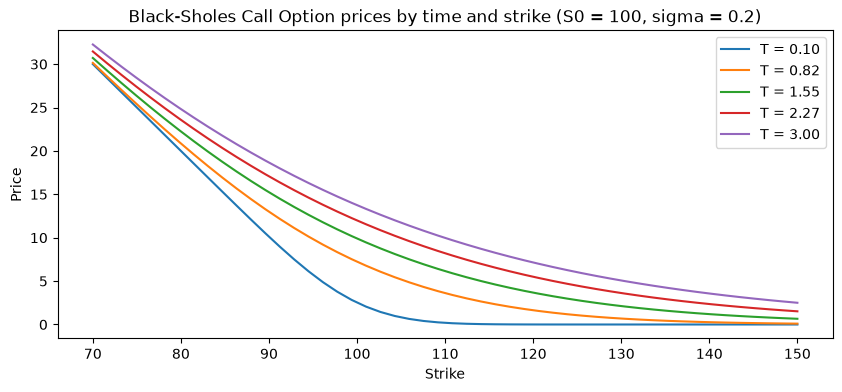

In [9]:
import matplotlib.pylab as plt

TT = np.linspace(0.1, 3., 5) # Maturity. array of 5 equally spaced values between 0.1, 3.0
strikes = np.linspace(70., 150, 50) # strike prices

plt.figure(figsize=(10,4))  # initializing new plot figure

for T in TT:
    plt.plot(strikes, 
             [blackscholes_call(S0, K, sigma, T) for K in strikes],
             label = 'T = %.2f' %T)

plt.legend()
plt.title('Black-Sholes Call Option prices by time and strike (S0 = 100, sigma = 0.2)')
plt.xlabel('Strike')
plt.ylabel('Price')

<div style="font-family: 'Times New Roman', serif;">  

#### 2. Pricing by integration  

**Stock price under GBM**
$$
S_t
  \stackrel{d}{=} S_0\exp\left\{-\frac{\sigma^2 t}{2} + \sigma Z\sqrt{t}\right\}
$$  


for any function $f:\mathbb{R}_+\to\mathbb{R}$  

$$
\mathbb{E}\left[f(S_T)\right] = 
\mathbb{E}\left[f\left(S_0\exp\left\{-\frac{\sigma^2 T}{2} + \sigma z\sqrt{T}\right\}\right)\right] =
\int_{\mathbb{R}}f\left(S_0\exp\left\{-\frac{\sigma^2 T}{2} + \sigma x\sqrt{T}\right\}\right)\varphi(x) dx
$$  
Where the $\varphi$ is the gaussian density funciton
$$\varphi(x) := \frac{1}{\sqrt{2\pi}}\exp\left\{-\frac{x^2}{2}\right\}$$

**European Call Option payoff**   
$$f(S_T) = \max(S_{T} - K, 0)$$

</div>

In [15]:
'''
quad(func, a, b, args = ()))

[INPUT]
  func: function to integrate
  a: lower limit  (can pass -np.inf as limit)
  b: upper limit  (can pass np.inf as limit)
  args: parameters required in func (except the first parameter which is the integration variable x)

[OUTPUT]
  1) integrated value
  2) absolute error estimate (maximum error)
'''

'\nquad(func, a, b, args = ()))\n\n[INPUT]\n  func: function to integrate\n  a: lower limit  (can pass -np.inf as limit)\n  b: upper limit  (can pass np.inf as limit)\n  args: parameters required in func (except the first parameter which is the integration variable x)\n\n[OUTPUT]\n  1) integrated value\n  2) absolute error estimate (maximum error)\n'

In [16]:
from scipy.integrate import quad

def black_scholes_call_price_integ(S0, K, T, sigma):
    """
    Computes the price of a European Call option in the Black-Scholes model by integration
    S0: initial value of the stock price
    K: strike
    T: time to expiry
    sigma: instantaneous volatility

    output: European Call option price

    """
    def integrad_blacksholes(x, S0, K, sigma, T):

        gaussianDensity = np.exp(- x*x/2) / np.sqrt(2*np.pi)
        ST = S0 * np.exp(-sigma*sigma*T/2 + sigma*x*np.sqrt(T))
        payoffFunction = max(ST-K,0) 

        return payoffFunction * gaussianDensity

    return quad(integrad_blacksholes, -20., 20., args = (S0, K, sigma, T)) 

In [17]:
S0, K, sigma, T = 100., 100., 0.2, 1.
black_scholes_call_price_integ(S0, K, T, sigma)

(7.965567455359225, 7.188058025508944e-08)

<div style="font-family: 'Times New Roman', serif;">  

#### 3. Pricing by simulation  

</div>

<div style="font-family: 'Times New Roman', serif;">  

**Stock price under GBM**
$$
S_t
  \stackrel{d}{=} S_0\exp\left\{-\frac{\sigma^2 t}{2} + \sigma Z\sqrt{t}\right\}
$$   

instead of computing expectation as integration (averaging over *every possible* instances)
$$
\mathbb{E}\left[f(S_T)\right] = 
\mathbb{E}\left[f\left(S_0\exp\left\{-\frac{\sigma^2 T}{2} + \sigma z\sqrt{T}\right\}\right)\right]
$$

exectation can be approximated as (averaging over every *realised* instances)
$$
\mathbb{E}[f(S_T)] \approx \frac{1}{n}\sum_{i=1}^{n}f\left(S_T^{(i)}\right),
$$

**European Call Option payoff**   
$$f(S_T) = \max(S_{T} - K, 0)$$

</div>

In [21]:
def black_scholes_call_price_simul(S0, K, T, sigma, n):
    """
    Computes the price of a European Call option in the Black-Scholes model by simulation
    S0: initial value of the stock price
    K: strike
    T: time to expiry
    sigma: instantaneous volatility
    n: number of samples (corresponding to the parameter N above)

    output: European Call option price

    """

    nn = np.random.normal(0., 1., n) #generate n random variable from standardized normal distribution.

    ST = S0 * np.exp(-sigma*sigma*T/2 + sigma*nn*np.sqrt(T)) # vector of n different stock price at maturity
    f = np.maximum(ST - K, 0) # np.maximum when handling vector


    return np.mean(f) # sum(f(ST))/n




In [22]:
S0, K, sigma, T, n = 100., 100., 0.2, 1., 1000000
black_scholes_call_price_simul(S0, K, T, sigma, n)

np.float64(7.975631593606154)

<div style="font-family: 'Times New Roman', serif;">  

#### 3-2. Observing convergence

</div>

<div style="font-family: 'Times New Roman', serif;">  

By the Central Limit Theorem, the sample mean $\hat{C}_n = \frac{1}{n}\sum_{i=1}^n f(S_T^{(i)})$ satifies:
$$\sqrt{n} \, (\hat{C}_n - C) \xrightarrow{d} \mathcal{N}\left(0, \sigma_{\text{payoff}}^2\right)$$
where $\sigma_{\text{payoff}}^2 = \mathrm{Var}(f(S_T))$  

The standard error (dispersion of the estimate): 
$$\mathrm{SE}(\hat{C}_n) = \frac{\sigma_{\text{payoff}}}{\sqrt{n}}$$


Therefore, the sample mean converges to the true mean with the convergence rate: $\mathcal{O}(1 / \sqrt{n})$

</div>

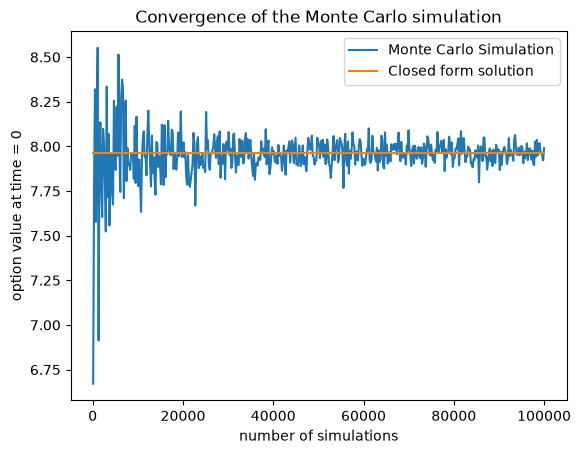

In [25]:
nn = np.linspace(100, 100000, 500).astype(int) # number of simulations

bs_simul_prices = [black_scholes_call_price_simul(S0, K, T, sigma, n) for n in nn]
true_price = blackscholes_call(S0, K, sigma, T)

plt.figure()
plt.plot(nn, bs_simul_prices, label = "Monte Carlo Simulation")
plt.plot(nn, [true_price for _ in nn], label = "Closed form solution")
plt.title("Convergence of the Monte Carlo simulation")
plt.xlabel("number of simulations")
plt.ylabel("option value at time = 0")
plt.legend()
plt.show()